In [1]:
import os, glob

In [2]:
dirs_datas_RA = glob.glob(os.path.join(r"./EyeMovementDetectorEvaluation/annotated_data/data used in the article/dots", "*_labelled_RA.mat"))
print(len(dirs_datas_RA))
print(dirs_datas_RA[0])

11
./EyeMovementDetectorEvaluation/annotated_data/data used in the article/dots/UL31_trial1_labelled_RA.mat


In [3]:
import scipy.io
import numpy as np
import pandas as pd

In [4]:
mat_data = scipy.io.loadmat(dirs_datas_RA[0])
print(mat_data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'ETdata', 'results', 'fpData'])


## 4. データの形式と内容

### 4.1 保存形式

データはMATLABのネイティブ形式である `.mat` ファイルに保存されている。各ファイルは、1名の参加者が1種類の刺激を見たときの記録に対応する。

各 `.mat` ファイルには、次のフィールドを持つ構造体 `ETdata` が含まれている。

| フィールド | 説明 |
| --- | --- |
| `sampFreq` | データ記録時のサンプリング周波数 |
| `viewDist` | 眼から画面までの距離 |
| `screenDim` | 画面の物理的な大きさ。単位はメートル |
| `screenRes` | 画面の解像度。単位はピクセル |
| `pos` | 各行が1サンプルを表す `n × 5` の行列 |


In [5]:
sampFreq = mat_data["ETdata"]["sampFreq"][0][0][0][0]
print(sampFreq)
viewDist = mat_data["ETdata"]["viewDist"][0][0][0][0]
print(viewDist)
screenDim = mat_data["ETdata"]["screenDim"][0][0][0]
print(screenDim)
screenRes = mat_data["ETdata"]["screenRes"][0][0][0]
print(screenRes)
print(mat_data["ETdata"]["pos"])

500
0.67
[0.38 0.3 ]
[1024  768]
[[array([[     nan,  19.    ,  17.    , 809.5808,  31.9125,   4.    ],
         [     nan,  19.    ,  17.    , 809.2269,  32.3705,   4.    ],
         [     nan,  19.    ,  16.    , 809.6081,  33.2183,   4.    ],
         ...,
         [     nan,  18.    ,  16.    , 824.4357, 559.6524,   6.    ],
         [     nan,  18.    ,  15.    , 824.0566, 559.9087,   6.    ],
         [     nan,  11.    ,  15.    , 607.0472, 508.2217,   6.    ]],
        shape=(1326, 6))                                               ]]


In [6]:
x_center, y_center = (screenRes-1)/2
print(x_center, y_center)

511.5 383.5


In [7]:
screenDim

array([0.38, 0.3 ])

### 4.2 `pos` の各列

| 列番号（MATLAB） | 内容 |
| ---: | --- |
| 1 | タイムスタンプ。単位はマイクロ秒 |
| 2 | 水平方向の瞳孔径 |
| 3 | 垂直方向の瞳孔径 |
| 4 | 視線のx座標 |
| 5 | 視線のy座標 |

名前の末尾に `labelled` が付く注釈済みの `.mat` ファイルでは、第6列が追加される。この列は各サンプルのラベル、すなわち手作業によるラベル付けの結果を表す。

### 4.3 イベントラベル

| ラベル値 | 原語 | 日本語 |
| ---: | --- | --- |
| 1 | Fixation | 固視 |
| 2 | Saccade | サッカード |
| 3 | Post-saccadic oscillation | サッカード後振動（PSO） |
| 4 | Smooth pursuit | 滑動性追従眼球運動 |
| 5 | Blink | 瞬目（まばたき） |
| 6 | Undefined | 未定義。他のいずれのカテゴリにも当てはまらないサンプル |

In [8]:
print(len(mat_data["ETdata"]["pos"][0][0]))
print(mat_data["ETdata"]["pos"][0][0])
print(len(mat_data["ETdata"]["pos"][0][0][0]))

for i in range(len(mat_data["ETdata"]["pos"][0][0])):
    print(i, mat_data["ETdata"]["pos"][0][0][i])
    if i>5:
        break

1326
[[     nan  19.      17.     809.5808  31.9125   4.    ]
 [     nan  19.      17.     809.2269  32.3705   4.    ]
 [     nan  19.      16.     809.6081  33.2183   4.    ]
 ...
 [     nan  18.      16.     824.4357 559.6524   6.    ]
 [     nan  18.      15.     824.0566 559.9087   6.    ]
 [     nan  11.      15.     607.0472 508.2217   6.    ]]
6
0 [     nan  19.      17.     809.5808  31.9125   4.    ]
1 [     nan  19.      17.     809.2269  32.3705   4.    ]
2 [     nan  19.      16.     809.6081  33.2183   4.    ]
3 [     nan  19.      18.     809.3832  34.5953   4.    ]
4 [     nan  19.      18.     808.428   36.3464   4.    ]
5 [     nan  19.      16.     808.4969  36.1827   4.    ]
6 [     nan  19.      17.     807.2485  36.4236   4.    ]


In [9]:
df_data = pd.DataFrame(mat_data["ETdata"]["pos"][0][0])
df_data[0] = (1/sampFreq)*df_data.index 
df_data[5] = df_data[5].astype('int64')

In [10]:
# 画面中心の位置に修正
df_data["pos_x"] = df_data[3] - x_center
df_data["pos_y"] = df_data[4] - y_center
df_data

,0,1,2,3,4,5,pos_x,pos_y
0,0.000,19.0,17.0,809.5808,31.9125,4,298.0808,-351.5875
1,0.002,19.0,17.0,809.2269,32.3705,4,297.7269,-351.1295
2,0.004,19.0,16.0,809.6081,33.2183,4,298.1081,-350.2817
3,0.006,19.0,18.0,809.3832,34.5953,4,297.8832,-348.9047
4,0.008,19.0,18.0,808.4280,36.3464,4,296.9280,-347.1536
...,...,...,...,...,...,...,...,...
1321,2.642,18.0,16.0,824.2378,561.5823,6,312.7378,178.0823
1322,2.644,18.0,16.0,824.3988,558.8741,6,312.8988,175.3741
1323,2.646,18.0,16.0,824.4357,559.6524,6,312.9357,176.1524
1324,2.648,18.0,15.0,824.0566,559.9087,6,312.5566,176.4087


In [11]:
# df_data["mov_pix_x"] = df_data[3].diff()
# df_data["mov_pix_y"] = df_data[4].diff()
# # df_data["mov_pix"] = (df_data["mov_pix_x"]**2 + df_data["mov_pix_y"]**2)**(1/2)
# df_data

In [12]:
print(sampFreq)
print(viewDist)
print(screenDim)
print(screenRes)

time_bin = 1/sampFreq

# np.degrees(np.arctan2(-1, 1))
# 引数の順番がx, yではなくy, xなので注意。
# https://www.naukri.com/code360/library/numpy-arctan2-in-python
def calc_deg(x_mov_pix, y_mov_pix):
    dist_x_mov_m = (x_mov_pix/screenRes[0]) * screenDim[0]
    dist_y_mov_m = (y_mov_pix/screenRes[1]) * screenDim[1]
    dist_mov_m = ((dist_x_mov_m**2)+(dist_y_mov_m**2))**(1/2)
    return np.degrees(np.arctan2(dist_mov_m, viewDist))

500
0.67
[0.38 0.3 ]
[1024  768]


In [13]:
df_data["degree"] = calc_deg(df_data["pos_x"], df_data["pos_y"])
df_data["mov_deg"] = df_data["degree"].diff()/time_bin
# df_data["mov_deg"] = calc_deg(df_data["mov_pix_x"], df_data["mov_pix_y"])
df_data

,0,1,2,3,4,5,pos_x,pos_y,degree,mov_deg
0,0.000,19.0,17.0,809.5808,31.9125,4,298.0808,-351.5875,14.745964,NaN
1,0.002,19.0,17.0,809.2269,32.3705,4,297.7269,-351.1295,14.728231,-8.866498
2,0.004,19.0,16.0,809.6081,33.2183,4,298.1081,-350.2817,14.714722,-6.754633
3,0.006,19.0,18.0,809.3832,34.5953,4,297.8832,-348.9047,14.677073,-18.824584
4,0.008,19.0,18.0,808.4280,36.3464,4,296.9280,-347.1536,14.616679,-30.197013
...,...,...,...,...,...,...,...,...,...,...
1321,2.642,18.0,16.0,824.2378,561.5823,6,312.7378,178.0823,11.417319,-23.962733
1322,2.644,18.0,16.0,824.3988,558.8741,6,312.8988,175.3741,11.377104,-20.107440
1323,2.646,18.0,16.0,824.4357,559.6524,6,312.9357,176.1524,11.390789,6.842667
1324,2.648,18.0,15.0,824.0566,559.9087,6,312.5566,176.4087,11.385045,-2.872359


In [14]:
import matplotlib.pyplot as plt

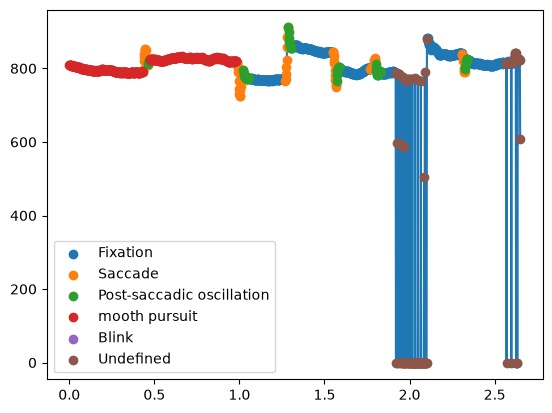

In [15]:
l_label = np.array([1,2,3,4,5,6])
d_label = {
    1: "Fixation",
    2: "Saccade",
    3: "Post-saccadic oscillation",
    4: "mooth pursuit",
    5: "Blink",
    6: "Undefined",
    }


for i_label in l_label:
    df_data_slice = df_data[df_data[5]==i_label]
    plt.scatter(df_data_slice[0], df_data_slice[3], label=d_label[i_label])
plt.plot(df_data[0], df_data[3], zorder=0)
plt.legend()
plt.show()

In [16]:
df_data_slice = df_data.iloc[1:-1]
df_data_slice

,0,1,2,3,4,5,pos_x,pos_y,degree,mov_deg
1,0.002,19.0,17.0,809.2269,32.3705,4,297.7269,-351.1295,14.728231,-8.866498
2,0.004,19.0,16.0,809.6081,33.2183,4,298.1081,-350.2817,14.714722,-6.754633
3,0.006,19.0,18.0,809.3832,34.5953,4,297.8832,-348.9047,14.677073,-18.824584
4,0.008,19.0,18.0,808.4280,36.3464,4,296.9280,-347.1536,14.616679,-30.197013
5,0.010,19.0,16.0,808.4969,36.1827,4,296.9969,-347.3173,14.621943,2.632353
...,...,...,...,...,...,...,...,...,...,...
1320,2.640,18.0,16.0,823.6103,565.4451,6,312.1103,181.9451,11.465244,23.088254
1321,2.642,18.0,16.0,824.2378,561.5823,6,312.7378,178.0823,11.417319,-23.962733
1322,2.644,18.0,16.0,824.3988,558.8741,6,312.8988,175.3741,11.377104,-20.107440
1323,2.646,18.0,16.0,824.4357,559.6524,6,312.9357,176.1524,11.390789,6.842667


860.637130437144


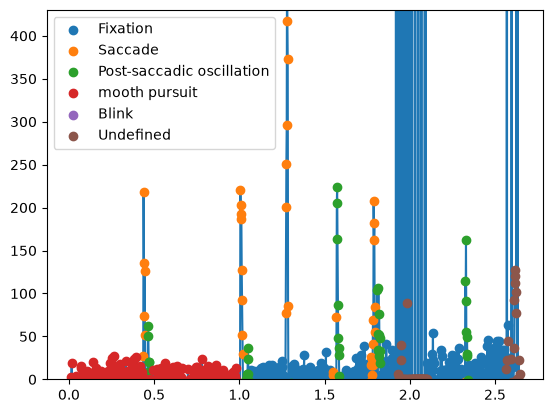

In [17]:
sigma = df_data_slice[1:-1]["mov_deg"].std()
print(sigma)
for i_label in l_label:
    df_data_slice = df_data.iloc[1:-1][df_data.iloc[1:-1][5]==i_label].copy()
    plt.scatter(df_data_slice[0], df_data_slice["mov_deg"], label=d_label[i_label])
plt.plot(df_data[0].iloc[1:-1], df_data["mov_deg"].iloc[1:-1], zorder=0)
plt.ylim(0, sigma*0.5)
plt.legend()
plt.show()

In [18]:
df_data["acc_deg"] = df_data["mov_deg"].diff()/time_bin
df_data["acc_deg_abs"] = df_data["acc_deg"].abs()
moving_average_window = 5
df_data["acc_deg_abs_moving_avg"] = df_data["acc_deg_abs"].rolling(moving_average_window).mean() # 前の3つとの平均。 [4:-2]
df_data


,0,1,2,3,4,5,pos_x,pos_y,degree,mov_deg,acc_deg,acc_deg_abs,acc_deg_abs_moving_avg
0,0.000,19.0,17.0,809.5808,31.9125,4,298.0808,-351.5875,14.745964,NaN,NaN,NaN,NaN
1,0.002,19.0,17.0,809.2269,32.3705,4,297.7269,-351.1295,14.728231,-8.866498,NaN,NaN,NaN
2,0.004,19.0,16.0,809.6081,33.2183,4,298.1081,-350.2817,14.714722,-6.754633,1.055933e+03,1.055933e+03,NaN
3,0.006,19.0,18.0,809.3832,34.5953,4,297.8832,-348.9047,14.677073,-18.824584,-6.034976e+03,6.034976e+03,NaN
4,0.008,19.0,18.0,808.4280,36.3464,4,296.9280,-347.1536,14.616679,-30.197013,-5.686214e+03,5.686214e+03,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1321,2.642,18.0,16.0,824.2378,561.5823,6,312.7378,178.0823,11.417319,-23.962733,-2.352549e+04,2.352549e+04,1.265760e+06
1322,2.644,18.0,16.0,824.3988,558.8741,6,312.8988,175.3741,11.377104,-20.107440,1.927646e+03,1.927646e+03,8.497200e+05
1323,2.646,18.0,16.0,824.4357,559.6524,6,312.9357,176.1524,11.390789,6.842667,1.347505e+04,1.347505e+04,4.312547e+05
1324,2.648,18.0,15.0,824.0566,559.9087,6,312.5566,176.4087,11.385045,-2.872359,-4.857513e+03,4.857513e+03,1.119582e+04


744545.4938912077


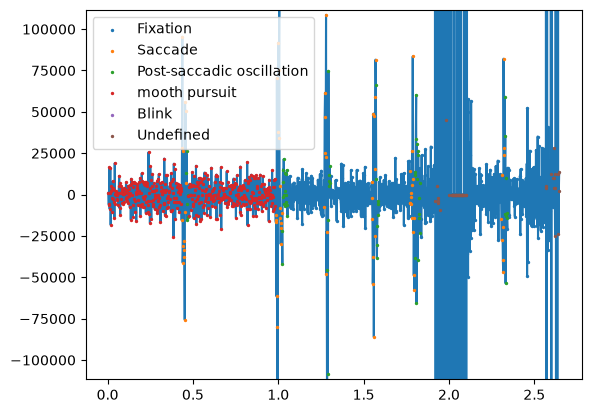

In [19]:
sigma = df_data["acc_deg"][2:-2].std()
sigma_range = 0.15

show_range_start = 0.1
show_range_end = 0.6

print(sigma)
for i_label in l_label:
    df_data_slice = df_data.iloc[2:-2][df_data.iloc[2:-2][5]==i_label].copy()
    plt.scatter(df_data_slice[0], df_data_slice["acc_deg"], label=d_label[i_label], s=2)
plt.plot(df_data[0].iloc[2:-2], df_data["acc_deg"].iloc[2:-2], zorder=0)
plt.ylim(-sigma*sigma_range, sigma*sigma_range)
# plt.xlim(show_range_start, show_range_end)

plt.legend()
plt.show()

725353.6846107534


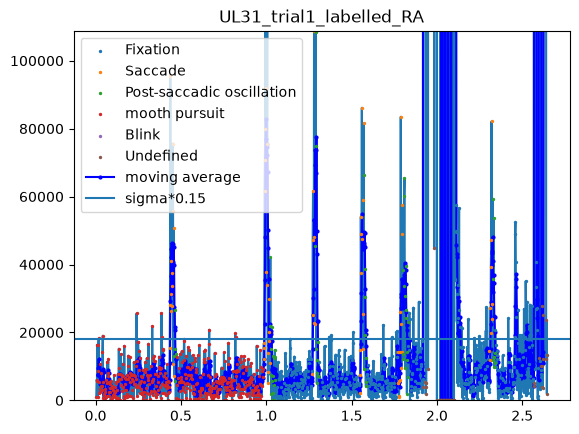

In [84]:
sigma = df_data["acc_deg_abs"][2:-2].std()
sigma_range = 0.15

show_range_start = 0.3
show_range_end = 1.5

sigma_slice = 0.025

print(sigma)
for i_label in l_label:
    df_data_slice = df_data.iloc[2:-2][df_data.iloc[2:-2][5]==i_label].copy()
    plt.scatter(df_data_slice[0], df_data_slice["acc_deg_abs"], label=d_label[i_label], s=2)
plt.plot(df_data[0].iloc[2:-2], df_data["acc_deg_abs"].iloc[2:-2], zorder=0)
plt.plot(
    df_data[0].iloc[moving_average_window:-2], 
    df_data["acc_deg_abs_moving_avg"].iloc[moving_average_window:-2], 
    zorder=0, c="b", marker="o", markersize=2, label="moving average")
plt.axhline(sigma*sigma_slice, label=f"sigma*{sigma_range}")
plt.ylim(0, sigma*sigma_range)
# plt.xlim(show_range_start, show_range_end)

plt.title(os.path.basename(dirs_datas_RA[0]).replace(".mat",""))
plt.legend()
plt.show()

In [21]:
sigma = df_data["acc_deg_abs"][2:-2].std()
sigma_range = 0.01

df_data["saccade_estimate"] = df_data["acc_deg_abs_moving_avg"]>sigma*sigma_range
df_data["saccade_ans"] = df_data[5]==2
display(df_data)

df_data_ma = df_data[moving_average_window:-2]
TP = (df_data_ma["saccade_estimate"] & df_data_ma["saccade_ans"]).sum()
FN = (~df_data_ma["saccade_estimate"] & df_data_ma["saccade_ans"]).sum()
FP = (df_data_ma["saccade_estimate"] & ~df_data_ma["saccade_ans"]).sum()
TN = (~df_data_ma["saccade_estimate"] & ~df_data_ma["saccade_ans"]).sum()
print(f"TP: {TP}, FN: {FN}, FP: {FP}, TN: {TN}")

,0,1,2,3,4,5,pos_x,pos_y,degree,mov_deg,acc_deg,acc_deg_abs,acc_deg_abs_moving_avg,saccade_estimate,saccade_ans
0,0.000,19.0,17.0,809.5808,31.9125,4,298.0808,-351.5875,14.745964,NaN,NaN,NaN,NaN,False,False
1,0.002,19.0,17.0,809.2269,32.3705,4,297.7269,-351.1295,14.728231,-8.866498,NaN,NaN,NaN,False,False
2,0.004,19.0,16.0,809.6081,33.2183,4,298.1081,-350.2817,14.714722,-6.754633,1.055933e+03,1.055933e+03,NaN,False,False
3,0.006,19.0,18.0,809.3832,34.5953,4,297.8832,-348.9047,14.677073,-18.824584,-6.034976e+03,6.034976e+03,NaN,False,False
4,0.008,19.0,18.0,808.4280,36.3464,4,296.9280,-347.1536,14.616679,-30.197013,-5.686214e+03,5.686214e+03,NaN,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1321,2.642,18.0,16.0,824.2378,561.5823,6,312.7378,178.0823,11.417319,-23.962733,-2.352549e+04,2.352549e+04,1.265760e+06,True,False
1322,2.644,18.0,16.0,824.3988,558.8741,6,312.8988,175.3741,11.377104,-20.107440,1.927646e+03,1.927646e+03,8.497200e+05,True,False
1323,2.646,18.0,16.0,824.4357,559.6524,6,312.9357,176.1524,11.390789,6.842667,1.347505e+04,1.347505e+04,4.312547e+05,True,False
1324,2.648,18.0,15.0,824.0566,559.9087,6,312.5566,176.4087,11.385045,-2.872359,-4.857513e+03,4.857513e+03,1.119582e+04,True,False


TP: 69, FN: 9, FP: 553, TN: 688


In [ ]:
l_label = np.array([1,2,3,4,5,6])
d_label = {
    1: "Fixation",
    2: "Saccade",
    3: "Post-saccadic oscillation",
    4: "mooth pursuit",
    5: "Blink",
    6: "Undefined",
    }
sigma_threshold_scale = 0.01


def calc_deg(x_mov_pix, y_mov_pix):
    dist_x_mov_m = (x_mov_pix/screenRes[0]) * screenDim[0]
    dist_y_mov_m = (y_mov_pix/screenRes[1]) * screenDim[1]
    dist_mov_m = ((dist_x_mov_m**2)+(dist_y_mov_m**2))**(1/2)
    return np.degrees(np.arctan2(dist_mov_m, viewDist))

def calc_saccade(data_mat, sigma_threshold_scale=0.01):
    # データ取り込み
    sampFreq = data_mat["ETdata"]["sampFreq"][0][0][0][0]
    viewDist = data_mat["ETdata"]["viewDist"][0][0][0][0]
    screenDim = data_mat["ETdata"]["screenDim"][0][0][0]
    screenRes = data_mat["ETdata"]["screenRes"][0][0][0]

    x_center, y_center = (screenRes-1)/2
    time_bin = 1/sampFreq

    df_data = pd.DataFrame(data_mat["ETdata"]["pos"][0][0])
    df_data[0] = (1/sampFreq)*df_data.index 
    df_data[5] = df_data[5].astype('int64')

    # ディスプレイの中心座標に
    df_data["pos_x"] = df_data[3] - x_center
    df_data["pos_y"] = df_data[4] - y_center

    # 角度に変換
    df_data["degree"] = calc_deg(df_data["pos_x"], df_data["pos_y"])
    # 角速度に変換
    df_data["mov_deg"] = df_data["degree"].diff()/time_bin
    # 角加速度に変換
    df_data["acc_deg"] = df_data["mov_deg"].diff()/time_bin

    # 角加速度の大きさを見たいので絶対値に変換
    df_data["acc_deg_abs"] = df_data["acc_deg"].abs()

    # 5フレーム分で移動平均。移動平均は前5フレーム分
    moving_average_window = 5
    df_data["acc_deg_abs_moving_avg"] = df_data["acc_deg_abs"].rolling(moving_average_window).mean() # 前の3つとの平均。 [4:-2]

    # 閾値作成のため、標準偏差を計算
    sigma = df_data["acc_deg"][2:-2].std()
    # 標準偏差に固定倍率をかけた値を閾値に、それ以上をサッカード。
    df_data["saccade_estimate"] = df_data["acc_deg_abs_moving_avg"]>sigma*sigma_threshold_scale
    # display(df_data.dtypes)
    # df_data["saccade_estimate"][df_data["acc_deg_abs_moving_avg"].isnull()] = np.nan



    # sigma_range = 0.15

    for i_label in l_label:
        df_data_slice = df_data.iloc[2:-2][df_data.iloc[2:-2][5]==i_label].copy()
        plt.scatter(df_data_slice[0], df_data_slice["acc_deg_abs"], label=d_label[i_label], s=2)
    plt.plot(df_data[0].iloc[2:-2], df_data["acc_deg_abs"].iloc[2:-2], zorder=0)
    plt.plot(
        df_data[0].iloc[moving_average_window:-2], 
        df_data["acc_deg_abs_moving_avg"].iloc[moving_average_window:-2], 
        zorder=0, c="b", marker="o", markersize=2)
    plt.axhline(sigma*sigma_threshold_scale)
    plt.ylim(0, sigma*sigma_range)
    # plt.xlim(show_range_start, show_range_end)
    plt.title(os.path.basename(dirs_datas_RA[0]).replace(".mat",""))
    plt.legend()
    plt.save()
    plt.show()


    
    np_estimate = df_data["saccade_estimate"].to_numpy()
    np_estimate = np_estimate.astype(object)
    np_null = df_data["acc_deg_abs_moving_avg"].isnull().to_numpy()
    np_null = np_null.astype(object)
    np_null[-2:] = True
    np_null = np_null.astype(bool)
    np_estimate[np_null] = np.nan
    # np_null = np_null.astype(object)
    # np_null[-2:] = np.nan
    # print(np_null)

    # 回答
    np_ans = (df_data[5]==2).to_numpy()

    return np_estimate, np_ans

def cacl_correct(np_estimate, np_ans):
    TP = (np_estimate & np_ans).sum()
    FN = (~np_estimate & np_ans).sum()
    FP = (np_estimate & ~np_ans).sum()
    TN = (~np_estimate & ~np_ans).sum()
    # print(f"TP: {TP}, FN: {FN}, FP: {FP}, TN: {TN}")
    return TP, FN, FP, TN

def remove_nan(np_estimate, np_ans):
    np_estimate_removed = np_estimate[~pd.isna(np_estimate)].astype(bool)
    np_ans_removed      = np_ans[~pd.isna(np_estimate)].astype(bool)
    return np_estimate_removed, np_ans_removed

[[   0   78  113 1127]
 [  34    0  372   41]
 [  30    0  397   18]
 [  48    0 1266    4]
 [  15    0  417   13]
 [  60    0  314   71]
 [  70    0 1578    2]
 [  31    0 1614    5]
 [  93    0 1220    3]
 [  11   16   40 1252]
 [  35    0  448   74]]
[np.float64(0.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(0.4074074074074074), np.float64(1.0)]
[np.float64(0.9088709677419354), np.float64(0.09927360774818401), np.float64(0.043373493975903614), np.float64(0.0031496062992125984), np.float64(0.030232558139534883), np.float64(0.18441558441558442), np.float64(0.0012658227848101266), np.float64(0.0030883261272390363), np.float64(0.0024529844644317253), np.float64(0.9690402476780186), np.float64(0.1417624521072797)]


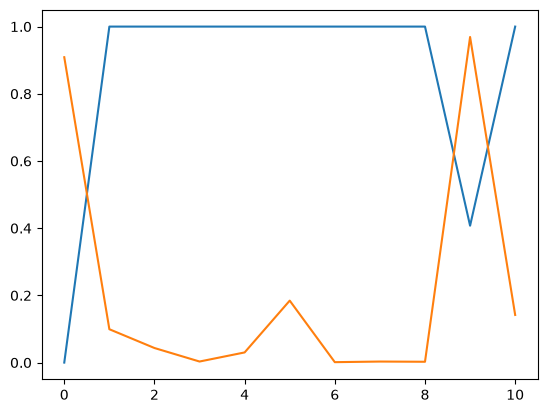

In [83]:
l_result = []
for dir_datas_RA in dirs_datas_RA:
    data_mat = scipy.io.loadmat(dir_datas_RA)
    np_estimate, np_ans = calc_saccade(data_mat, sigma_threshold_scale=0.15)
    # print(type(result))
    # print(len(result))
    # print(~pd.isna(result))
    # print(result[~pd.isna(result)])
    # print(len(result[~pd.isna(result)]))

    # np_estimate = np_estimate[~pd.isna(np_estimate)].astype(bool)
    # np_ans = np_ans[~pd.isna(np_estimate)].astype(bool)
    # print(len(np_estimate))
    np_estimate, np_ans = remove_nan(np_estimate, np_ans)

    # print(np_estimate.dtype)
    # print(np_ans.dtype)
    # print(len(np_estimate))
    # print(len(np_ans))

    # print(np_estimate)
    # print(np_estimate&np_ans)

    TP, FN, FP, TN = cacl_correct(np_estimate, np_ans)
    l_result.append([TP, FN, FP, TN].copy())

    # break
print(np.array(l_result))


l_TP_rate = [i[0]/(i[0]+i[1]) for i in l_result]
l_TN_rate = [i[3]/(i[2]+i[3]) for i in l_result]
print(l_TP_rate)
print(l_TN_rate)
plt.plot(l_TP_rate)
plt.plot(l_TN_rate)
plt.show()

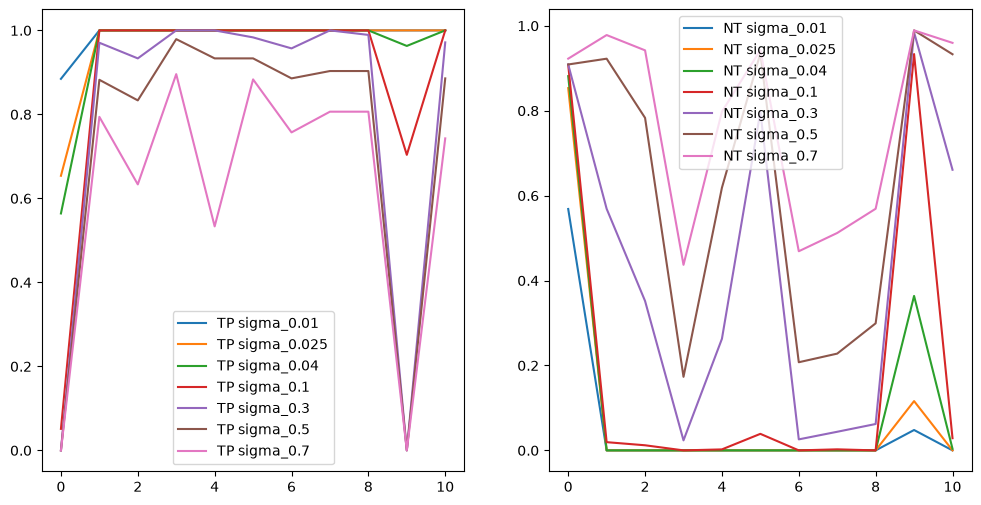

In [73]:

l_sigma_threshold_scale = [0.01, 0.025, 0.04, 0.1, 0.3, 0.5, 0.7]

fig, axes = plt.subplots(1,2, figsize=(12,6))

for sigma_threshold_scale in l_sigma_threshold_scale:
    l_result = []
    for dir_datas_RA in dirs_datas_RA:
        data_mat = scipy.io.loadmat(dir_datas_RA)
        np_estimate, np_ans = calc_saccade(data_mat, sigma_threshold_scale=sigma_threshold_scale)
        np_estimate, np_ans = remove_nan(np_estimate, np_ans)
        TP, FN, FP, TN = cacl_correct(np_estimate, np_ans)
        l_result.append([TP, FN, FP, TN].copy())

    # print(np.array(l_result))


    l_TP_rate = [i[0]/(i[0]+i[1]) for i in l_result]
    l_TN_rate = [i[3]/(i[2]+i[3]) for i in l_result]
    # print(l_TP_rate)
    # print(l_TN_rate)
    axes[0].plot(l_TP_rate, label="TP sigma_{:.3}".format(sigma_threshold_scale))
    axes[0].legend()
    axes[1].plot(l_TN_rate, label="NT sigma_{:.3}".format(sigma_threshold_scale))
    axes[1].legend()
plt.show()